In [2]:
data <- read.csv("../../data/leaving_home_clean_data.csv")
head(data)

,country,year,region,region_2groups,leave_age_total,leave_age_men,leave_age_women,gender_gap,price_income_ratio,owners_pct,gdp_per_capita_eur,employment_rate_20_64
,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Austria,2016,Western,North/West,25.3,26.3,24.2,2.1,105.63,55.0,40690,74.8
2,Austria,2017,Western,North/West,25.2,26.0,24.4,1.6,108.71,55.0,41760,75.4
3,Austria,2018,Western,North/West,25.6,26.3,24.8,1.5,111.67,55.4,43360,76.2
4,Austria,2019,Western,North/West,25.4,26.2,24.6,1.6,115.99,55.2,44570,76.8
5,Austria,2020,Western,North/West,25.5,26.4,24.6,1.8,123.96,55.3,42650,74.8
6,Austria,2021,Western,North/West,25.3,26.3,24.4,1.9,130.92,54.2,45380,75.6


In [3]:
d2024 <- subset(data, year == 2024)
d2016 <- subset(data, year == 2016)

d2024$price_change <- d2024$price_income_ratio -
  d2016$price_income_ratio[match(d2024$country, d2016$country)]

d2024$gdp_k <- d2024$gdp_per_capita_eur / 1000

nrow(d2024)
d2024[, c("country", "leave_age_total", "gdp_k", "price_change",
          "employment_rate_20_64", "owners_pct")]

[1] 27

,country,leave_age_total,gdp_k,price_change,employment_rate_20_64,owners_pct
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
9,Austria,25.3,54.47,9.56,77.4,54.5
18,Belgium,26.2,52.27,-3.10,72.3,70.3
27,Bulgaria,28.2,16.34,-19.69,76.8,86.0
36,Croatia,31.3,22.55,2.65,73.6,91.0
45,Cyprus,27.2,37.24,-5.77,80.1,69.4
54,Czechia,25.8,29.51,15.27,82.3,74.7
63,Denmark,21.7,66.97,5.85,80.2,60.9
72,Estonia,22.4,29.01,8.33,81.8,79.3
81,Finland,21.4,49.13,-22.98,77.0,68.1


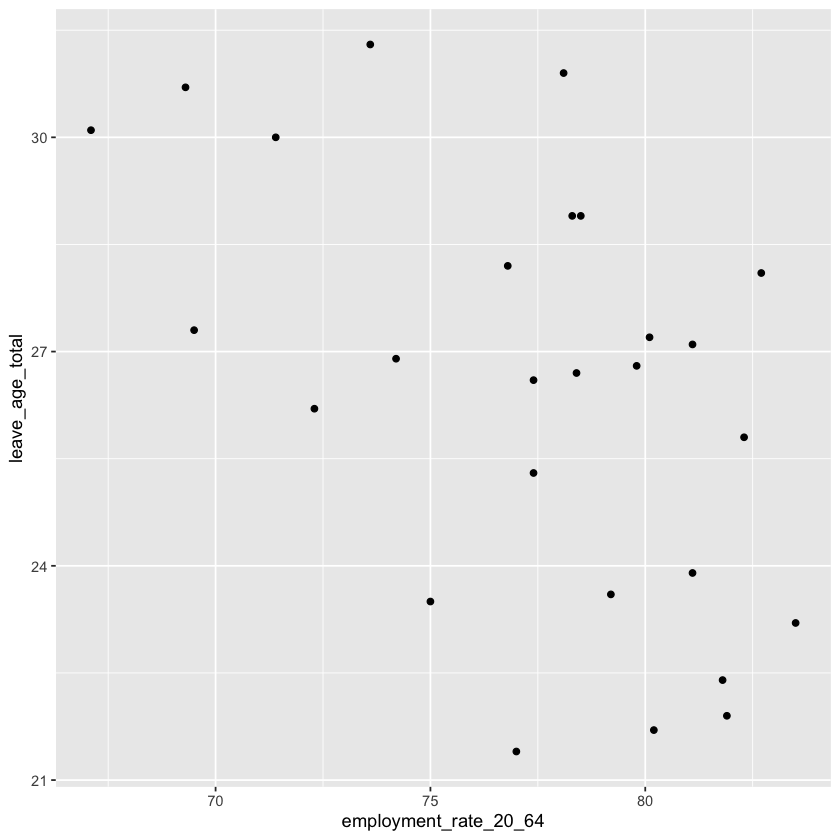

In [4]:
library(ggplot2)

ggplot(d2024, aes(x = employment_rate_20_64, y = leave_age_total)) +
  geom_point()

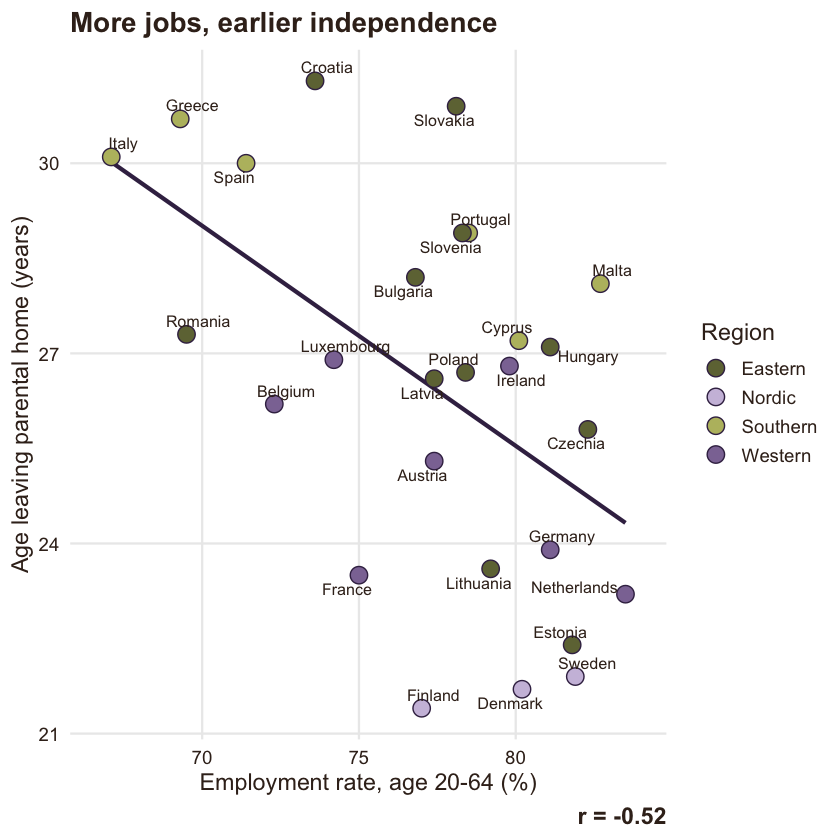

In [16]:
library(ggplot2)
library(ggrepel)

# --- our colours ---
deep_purple <- "#3E2C52"
deep_brown  <- "#3B2A20"
region_colours <- c(Nordic   = "#CDBFDD",   # light lavender
                    Western  = "#8C76A3",   # dusty purple
                    Southern = "#B9BC6E",   # muted chartreuse
                    Eastern  = "#6F7342")   # deep olive

# --- our style, reused for every chart ---
my_theme <- theme_minimal(base_size = 14) +
  theme(text       = element_text(colour = deep_brown),
        axis.text  = element_text(colour = deep_brown),
        plot.title = element_text(face = "bold"),
        panel.grid.minor = element_blank())

# --- the chart ---
r_emp <- cor(d2024$employment_rate_20_64, d2024$leave_age_total)

p_emp <- ggplot(d2024, aes(x = employment_rate_20_64, y = leave_age_total)) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE,
              colour = deep_purple, linewidth = 1.2) +
  geom_point(aes(fill = region), shape = 21, size = 4.5,
             colour = deep_purple, stroke = 0.6) +
  geom_text_repel(aes(label = country), size = 3.4, colour = deep_brown,
                  seed = 1) +
  scale_fill_manual(values = region_colours) +
  scale_x_continuous(expand = expansion(mult = 0.08)) +
  labs(title = "More jobs, earlier independence",
       x = "Employment rate, age 20-64 (%)",
       y = "Age leaving parental home (years)",
       fill = "Region",
       caption = paste0("r = ", round(r_emp, 2))) +
  my_theme +
  theme(plot.caption = element_text(size = 14, face = "bold"))

p_emp
ggsave("employment_big.png", p_emp, width = 10, height = 6, dpi = 300, bg = "white")

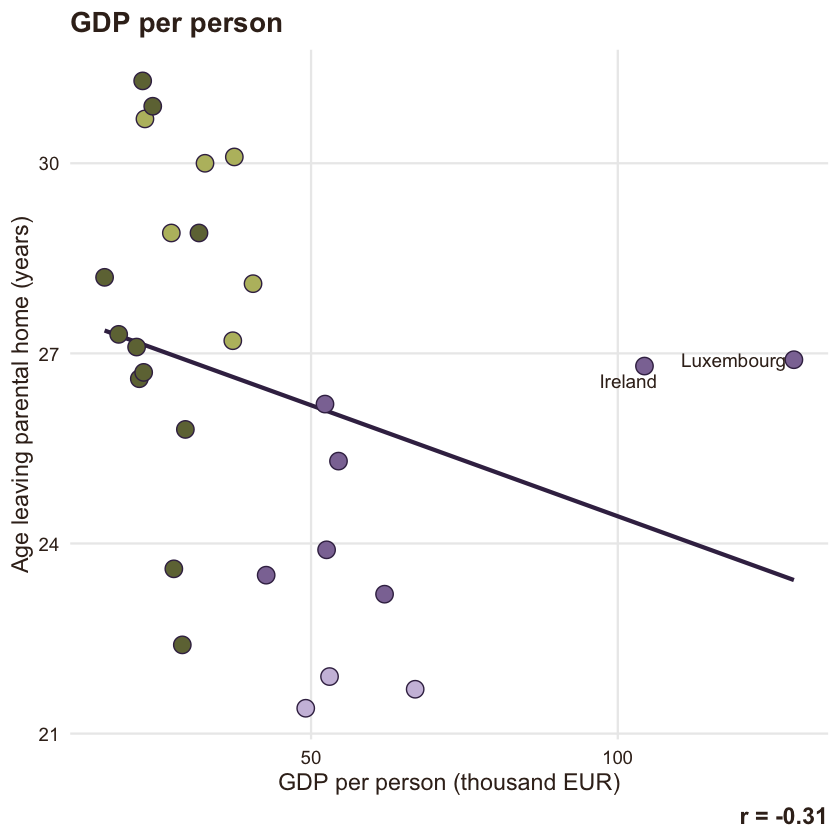

In [10]:
outliers <- subset(d2024, country %in% c("Ireland", "Luxembourg"))
r_gdp <- cor(d2024$gdp_k, d2024$leave_age_total)

p_gdp <- ggplot(d2024, aes(x = gdp_k, y = leave_age_total)) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE,
              colour = deep_purple, linewidth = 1.2) +
  geom_point(aes(fill = region), shape = 21, size = 4.5,
             colour = deep_purple, stroke = 0.6) +
  geom_text_repel(data = outliers, aes(label = country),
                  size = 4, colour = deep_brown, seed = 1) +
  scale_fill_manual(values = region_colours) +
  labs(title = "GDP per person",
       x = "GDP per person (thousand EUR)",
       y = "Age leaving parental home (years)",
       caption = paste0("r = ", round(r_gdp, 2))) +
  my_theme +
  theme(legend.position = "none",
        plot.caption = element_text(size = 14, face = "bold"))

p_gdp
ggsave("gdp_small.png", p_gdp, width = 6, height = 5, dpi = 300, bg = "white")

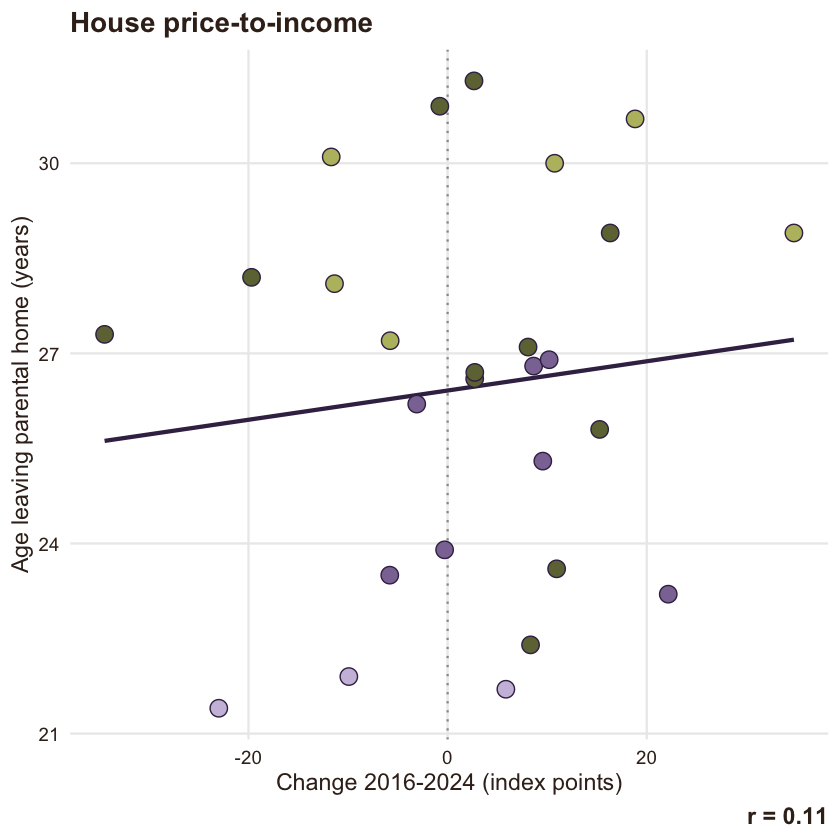

In [11]:
r_price <- cor(d2024$price_change, d2024$leave_age_total)

p_price <- ggplot(d2024, aes(x = price_change, y = leave_age_total)) +
  geom_vline(xintercept = 0, colour = "grey60", linetype = "dotted") +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE,
              colour = deep_purple, linewidth = 1.2) +
  geom_point(aes(fill = region), shape = 21, size = 4.5,
             colour = deep_purple, stroke = 0.6) +
  scale_fill_manual(values = region_colours) +
  labs(title = "House price-to-income",
       x = "Change 2016-2024 (index points)",
       y = "Age leaving parental home (years)",
       caption = paste0("r = ", round(r_price, 2))) +
  my_theme +
  theme(legend.position = "none",
        plot.caption = element_text(size = 14, face = "bold"))

p_price
ggsave("price_small.png", p_price, width = 6, height = 5, dpi = 300, bg = "white")

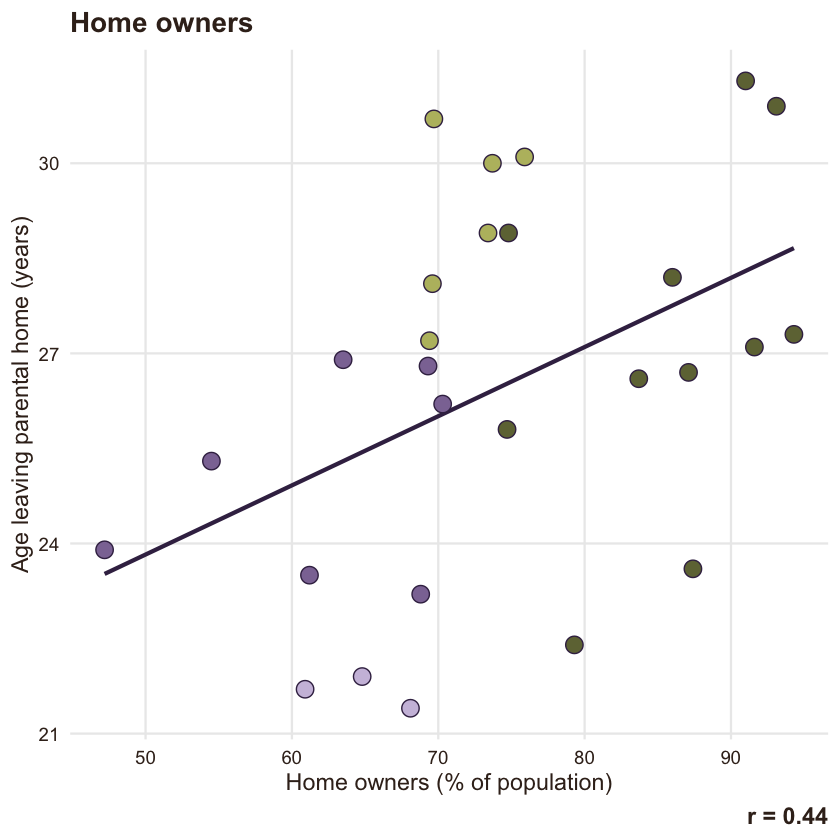

In [12]:
r_owners <- cor(d2024$owners_pct, d2024$leave_age_total)

p_owners <- ggplot(d2024, aes(x = owners_pct, y = leave_age_total)) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE,
              colour = deep_purple, linewidth = 1.2) +
  geom_point(aes(fill = region), shape = 21, size = 4.5,
             colour = deep_purple, stroke = 0.6) +
  scale_fill_manual(values = region_colours) +
  labs(title = "Home owners",
       x = "Home owners (% of population)",
       y = "Age leaving parental home (years)",
       caption = paste0("r = ", round(r_owners, 2))) +
  my_theme +
  theme(legend.position = "none",
        plot.caption = element_text(size = 14, face = "bold"))

p_owners
ggsave("owners_small.png", p_owners, width = 6, height = 5, dpi = 300, bg = "white")

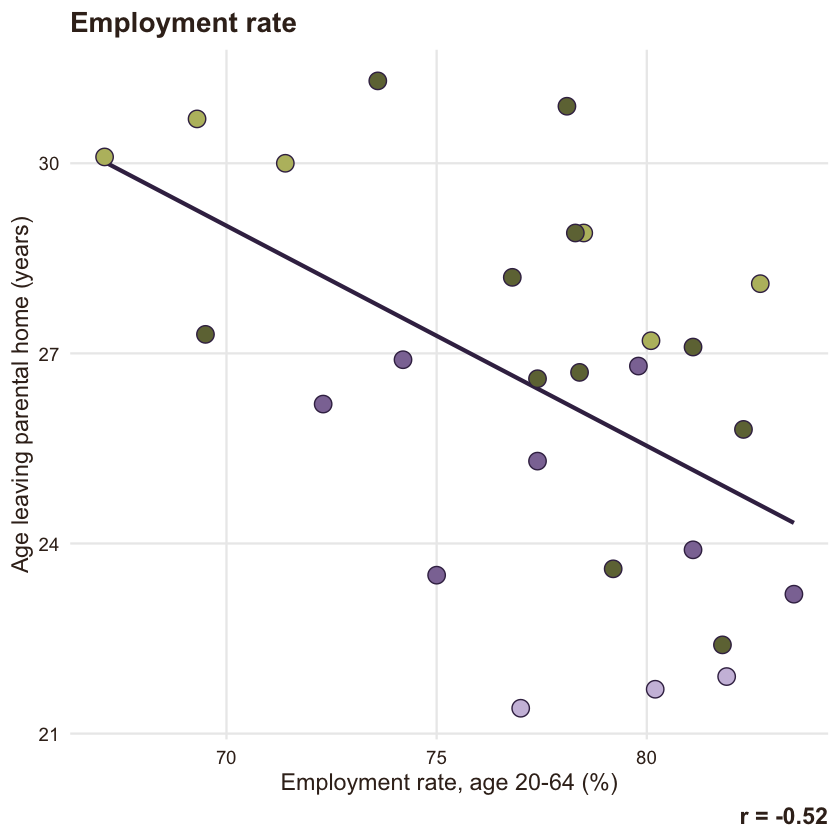

In [13]:
r_emp <- cor(d2024$employment_rate_20_64, d2024$leave_age_total)

p_emp_small <- ggplot(d2024, aes(x = employment_rate_20_64, y = leave_age_total)) +
  geom_smooth(method = "lm", formula = y ~ x, se = FALSE,
              colour = deep_purple, linewidth = 1.2) +
  geom_point(aes(fill = region), shape = 21, size = 4.5,
             colour = deep_purple, stroke = 0.6) +
  scale_fill_manual(values = region_colours) +
  labs(title = "Employment rate",
       x = "Employment rate, age 20-64 (%)",
       y = "Age leaving parental home (years)",
       caption = paste0("r = ", round(r_emp, 2))) +
  my_theme +
  theme(legend.position = "none",
        plot.caption = element_text(size = 14, face = "bold"))

p_emp_small
ggsave("employment_small.png", p_emp_small, width = 6, height = 5, dpi = 300, bg = "white")

factor,r,direction
<chr>,<dbl>,<chr>
Employment rate,-0.5198044,Leave earlier
Home owners,0.4445406,Leave later
GDP per person,-0.3061718,Leave earlier
House price-to-income change,0.1148628,Leave later


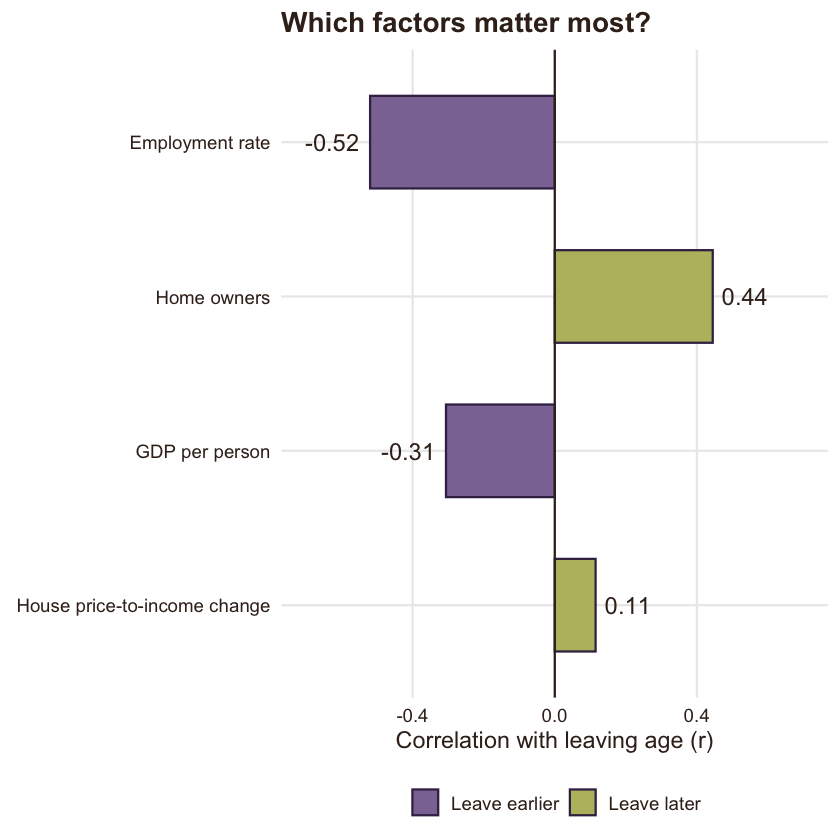

In [14]:
r_table <- data.frame(
  factor = c("Employment rate", "Home owners", "GDP per person", "House price-to-income change"),
  r      = c(r_emp, r_owners, r_gdp, r_price))
r_table$direction <- ifelse(r_table$r < 0, "Leave earlier", "Leave later")
r_table

p_r <- ggplot(r_table, aes(x = r, y = reorder(factor, abs(r)), fill = direction)) +
  geom_col(width = 0.6, colour = deep_purple) +
  geom_vline(xintercept = 0, colour = deep_brown) +
  geom_text(aes(label = round(r, 2), hjust = ifelse(r < 0, 1.2, -0.2)),
            colour = deep_brown, size = 5) +
  scale_fill_manual(values = c("Leave earlier" = "#8C76A3", "Leave later" = "#B9BC6E")) +
  scale_x_continuous(limits = c(-0.7, 0.7)) +
  labs(title = "Which factors matter most?",
       x = "Correlation with leaving age (r)", y = NULL, fill = NULL) +
  my_theme +
  theme(legend.position = "bottom")

p_r
ggsave("correlations_bar.png", p_r, width = 9, height = 5, dpi = 300, bg = "white")